In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [62]:
df=pd.read_csv("/content/telecom_usage_mixed.csv")

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   monthly_minutes      244 non-null    object 
 1   user_id              245 non-null    object 
 2   monthly_data_mb      236 non-null    float64
 3   monthly_sms          240 non-null    float64
 4   monthly_data_mb_dup  236 non-null    float64
 5   contract_months      248 non-null    float64
 6   churn_next_month     241 non-null    float64
 7   plan_type            232 non-null    object 
 8   has_family_plan      236 non-null    object 
 9   overdue_payments     242 non-null    float64
dtypes: float64(6), object(4)
memory usage: 20.2+ KB


##Remove the missing rows and duplicate rows of user_id

In [64]:
df['user_id'].duplicated().sum()

np.int64(18)

In [65]:
df['user_id'] = df['user_id'].replace('', pd.NA)
df = df.dropna(subset=['user_id'])
df['user_id'].isna().sum()

np.int64(0)

In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 245 entries, 0 to 256
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   monthly_minutes      233 non-null    object 
 1   user_id              245 non-null    object 
 2   monthly_data_mb      227 non-null    float64
 3   monthly_sms          228 non-null    float64
 4   monthly_data_mb_dup  227 non-null    float64
 5   contract_months      236 non-null    float64
 6   churn_next_month     230 non-null    float64
 7   plan_type            220 non-null    object 
 8   has_family_plan      225 non-null    object 
 9   overdue_payments     230 non-null    float64
dtypes: float64(6), object(4)
memory usage: 21.1+ KB


In [67]:
df.head()

,monthly_minutes,user_id,monthly_data_mb,monthly_sms,monthly_data_mb_dup,contract_months,churn_next_month,plan_type,has_family_plan,overdue_payments
0,1351.0,U70000,1213.0,15.0,1213.0,17.0,0.0,Basic,No,1.0
1,1041.0,U70001,1215.0,12.0,1215.0,14.0,1.0,UNLIMITED,No,2.0
2,1182.0,U70002,1546.0,199.0,1546.0,3.0,NaN,BASIC,Yes,2.0
3,1281.0,U70003,2014.0,183.0,2014.0,33.0,0.0,Basic,No,0.0
4,1482.0,U70004,6308.0,308.0,6308.0,16.0,0.0,Standard,N,1.0


In [68]:
df['user_id'].nunique()

238

##Remove the duplicate rows

In [69]:
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)
print(df.duplicated().sum())


7
0


##convet incorrect data *types*

In [70]:
cols = [
    'monthly_sms',
    'contract_months',
    'churn_next_month',
    'overdue_payments'
]

df[cols] = df[cols].astype('Int64')

In [71]:
df.dtypes

,0
monthly_minutes,object
user_id,object
monthly_data_mb,float64
monthly_sms,Int64
monthly_data_mb_dup,float64
contract_months,Int64
churn_next_month,Int64
plan_type,object
has_family_plan,object
overdue_payments,Int64


##drop duplicate columns

In [72]:
df['monthly_data_mb'].equals(df['monthly_data_mb_dup'])

True

In [73]:
df.drop('monthly_data_mb_dup', axis=1, inplace=True)

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 238 entries, 0 to 249
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   monthly_minutes   227 non-null    object 
 1   user_id           238 non-null    object 
 2   monthly_data_mb   220 non-null    float64
 3   monthly_sms       221 non-null    Int64  
 4   contract_months   229 non-null    Int64  
 5   churn_next_month  224 non-null    Int64  
 6   plan_type         213 non-null    object 
 7   has_family_plan   218 non-null    object 
 8   overdue_payments  223 non-null    Int64  
dtypes: Int64(4), float64(1), object(4)
memory usage: 19.5+ KB


In [77]:
df.head()

,monthly_minutes,user_id,monthly_data_mb,monthly_sms,contract_months,churn_next_month,plan_type,has_family_plan,overdue_payments
0,1351.0,U70000,1213.0,15,17,0,Basic,No,1
1,1041.0,U70001,1215.0,12,14,1,UNLIMITED,No,2
2,1182.0,U70002,1546.0,199,3,<NA>,BASIC,Yes,2
3,1281.0,U70003,2014.0,183,33,0,Basic,No,0
4,1482.0,U70004,6308.0,308,16,0,Standard,N,1


In [78]:
df['monthly_minutes'].isna().sum()

np.int64(11)

In [79]:
df['monthly_minutes'].describe()

,monthly_minutes
count,227
unique,198
top,unknown
freq,5


##Replace unknown and nan values in monthly_minutes


In [81]:
(df['monthly_minutes'] == 'unknown').sum()

np.int64(5)

In [86]:
df['monthly_minutes'] = df['monthly_minutes'].replace('unknown', np.nan)
df['monthly_minutes'] = df['monthly_minutes'].replace(' ', np.nan)


In [90]:
df['monthly_minutes'] = pd.to_numeric(
    df['monthly_minutes'], errors='coerce'
)
df['monthly_minutes'].dtype

dtype('float64')

In [91]:
df['monthly_minutes'] = df['monthly_minutes'].fillna(df['monthly_minutes'].median())

In [92]:
df['monthly_minutes'].isnull().sum()

np.int64(0)

Find outliers in monthly_minutes

In [93]:
Q1 = df['monthly_minutes'].quantile(0.25)
Q3 = df['monthly_minutes'].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 876.5
Q3: 1216.75
IQR: 340.25


In [94]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit:", lower)
print("Upper limit:", upper)

Lower limit: 366.125
Upper limit: 1727.125


In [95]:
outliers = df[(df['monthly_minutes'] < lower) |(df['monthly_minutes'] > upper)]
print(outliers['monthly_minutes'])

37      1791.0
118    39600.0
145       84.0
166    50950.0
215      364.0
Name: monthly_minutes, dtype: float64


In [98]:
df['monthly_minutes'] = df['monthly_minutes'].clip(lower=lower,upper=upper)

##Fill missing values , outliers in monthly_data_mb

In [99]:
df['monthly_data_mb'].isnull().sum()

np.int64(18)

In [101]:
df['monthly_data_mb'].describe()

,monthly_data_mb
count,220.000000
mean,2005.800000
std,2192.369389
min,0.000000
25%,392.500000
50%,1385.500000
75%,2603.000000
max,14873.000000


In [103]:
df['monthly_data_mb'] = df['monthly_data_mb'].fillna(df['monthly_data_mb'].median())
df['monthly_data_mb'].isnull().sum()

np.int64(0)

In [104]:
Q1 = df['monthly_data_mb'].quantile(0.25)
Q3 = df['monthly_data_mb'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower:", lower)
print("Upper:", upper)

Q1: 461.75
Q3: 2533.0
IQR: 2071.25
Lower: -2645.125
Upper: 5639.875


In [105]:
outliers = df[
    (df['monthly_data_mb'] < lower) |
    (df['monthly_data_mb'] > upper)
]

print(outliers['monthly_data_mb'])
print("Total outliers:", len(outliers))

4       6308.0
16      7175.0
23      7862.0
34      5988.0
38     12897.0
50      5879.0
77      6738.0
101     6662.0
104    14873.0
130     9037.0
143     5845.0
150     8584.0
160     6153.0
162     6466.0
191     5826.0
222     6317.0
Name: monthly_data_mb, dtype: float64
Total outliers: 16


In [106]:
df['monthly_data_mb'] = df['monthly_data_mb'].clip(lower=lower,upper=upper)


##Replace missing values and outliers in monthly_sms

In [108]:
df['monthly_sms'].isnull().sum()

np.int64(17)

In [109]:
df['monthly_sms'].describe()

,monthly_sms
count,221.0
mean,264.556561
std,146.113787
min,5.0
25%,145.0
50%,298.0
75%,391.0
max,498.0


In [111]:
df['monthly_sms'] = df['monthly_sms'].fillna(df['monthly_sms'].median())
df['monthly_sms'].isnull().sum()

np.int64(0)

In [112]:
Q1 = df['monthly_sms'].quantile(0.25)
Q3 = df['monthly_sms'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower)
print("Upper limit:", upper)

Q1: 157.75
Q3: 387.75
IQR: 230.0
Lower limit: -187.25
Upper limit: 732.75


In [113]:
outliers = df[(df['monthly_sms'] < lower) | (df['monthly_sms'] > upper)]
print(outliers['monthly_sms'])
print("Total outliers:", len(outliers))

Series([], Name: monthly_sms, dtype: Int64)
Total outliers: 0


##Replace missing values and outliers in contract_months

In [115]:
df['contract_months'].isnull().sum()

np.int64(9)

In [117]:
df['contract_months'].describe()

,contract_months
count,229.0
mean,17.39738
std,10.181002
min,0.0
25%,9.0
50%,17.0
75%,26.0
max,35.0


In [119]:
df['contract_months'] = df['contract_months'].fillna(df['contract_months'].median())
df['contract_months'].isnull().sum()

np.int64(0)

In [120]:
Q1 = df['contract_months'].quantile(0.25)
Q3 = df['contract_months'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit:", lower)
print("Upper limit:", upper)


Lower limit: -16.5
Upper limit: 51.5


In [121]:
outliers = df[(df['contract_months'] < lower) |(df['contract_months'] > upper)]
print(outliers['contract_months'])
print("Total outliers:", len(outliers))

Series([], Name: contract_months, dtype: Int64)
Total outliers: 0


##fill missing values in churn_next_month

In [122]:
df['churn_next_month'].isnull().sum()

np.int64(14)

In [123]:
df['churn_next_month'].unique()

<IntegerArray>
[0, 1, <NA>]
Length: 3, dtype: Int64

In [126]:
df['churn_next_month'] = df['churn_next_month'].fillna(df['churn_next_month'].mode()[0])
df['churn_next_month'].isnull().sum()

np.int64(0)

##plan_type

In [127]:
df['plan_type'].isnull().sum()

np.int64(25)

In [129]:
df['plan_type'] = df['plan_type'].replace(r'^\s*$', pd.NA, regex=True)

In [130]:
df['plan_type'].unique()

array(['Basic', 'UNLIMITED', 'BASIC', 'Standard', nan, 'STANDARD', 'Bsic',
       'Unlimited', 'Basi', 'Basc', 'Standrd', 'Unliited', 'nlimited',
       'Ulimited', 'Unimited', 'Unlimitd', 'Baic', 'Unlmited', 'Sandard',
       'Stndard', 'tandard', 'asic', 'Stadard'], dtype=object)

In [131]:
df['plan_type'] = df['plan_type'].str.strip().str.lower()

In [132]:
corrections = {
    'basic': 'Basic',
    'bsic': 'Basic',
    'basi': 'Basic',
    'basc': 'Basic',
    'baic': 'Basic',
    'asic': 'Basic',

    'standard': 'Standard',
    'standrd': 'Standard',
    'sandard': 'Standard',
    'stndard': 'Standard',
    'tandard': 'Standard',
    'stadard': 'Standard',

    'unlimited': 'Unlimited',
    'unliited': 'Unlimited',
    'nlimited': 'Unlimited',
    'ulimited': 'Unlimited',
    'unimited': 'Unlimited',
    'unlimitd': 'Unlimited',
    'unlmited': 'Unlimited'
}

df['plan_type'] = df['plan_type'].replace(corrections)

In [133]:
df['plan_type'] = df['plan_type'].fillna(df['plan_type'].mode()[0])

In [134]:
print(df['plan_type'].unique())

print(df['plan_type'].value_counts(dropna=False))

['Basic' 'Unlimited' 'Standard']
plan_type
Basic        107
Unlimited     66
Standard      65
Name: count, dtype: int64


##has_family_plan

In [135]:
df['has_family_plan'].isnull().sum()

np.int64(20)

In [136]:
df['has_family_plan'].unique()

array(['No', 'Yes', 'N', 'es', 'o', 'YES', nan, 'NO', 'Ys', 'Ye'],
      dtype=object)

In [137]:
df['has_family_plan'] = (df['has_family_plan'].str.strip().str.lower())

In [138]:
corrections = {
    'yes': 'yes',
    'y': 'yes',
    'es': 'yes',
    'ys': 'yes',
    'ye': 'yes',

    'no': 'no',
    'n': 'no',
    'o': 'no'
}

df['has_family_plan'] = df['has_family_plan'].replace(corrections)

In [139]:
df['has_family_plan'] = df['has_family_plan'].fillna(df['has_family_plan'].mode()[0])

In [140]:
df['has_family_plan'] = df['has_family_plan'].map({
    'yes': 1,
    'no': 0
})

In [141]:
print(df['has_family_plan'].unique())

print(df['has_family_plan'].isnull().sum())

[0 1]
0


##filling missing values and outliers in overdue_payments

In [142]:
df['overdue_payments'].isnull().sum()

np.int64(15)

In [143]:
df['overdue_payments'].describe()

,overdue_payments
count,223.0
mean,1.394619
std,1.093127
min,0.0
25%,0.0
50%,1.0
75%,2.0
max,3.0


In [144]:
df['overdue_payments'].unique()

<IntegerArray>
[1, 2, 0, 3, <NA>]
Length: 5, dtype: Int64

In [146]:
df['overdue_payments'] = df['overdue_payments'].fillna(df['overdue_payments'].median())
df['overdue_payments'].isnull().sum()

np.int64(0)

In [148]:
df.isnull().sum()

,0
monthly_minutes,0
user_id,0
monthly_data_mb,0
monthly_sms,0
contract_months,0
churn_next_month,0
plan_type,0
has_family_plan,0
overdue_payments,0


##Perfoming Data Analysis

#Univariate

Monthly Minutes Distribution

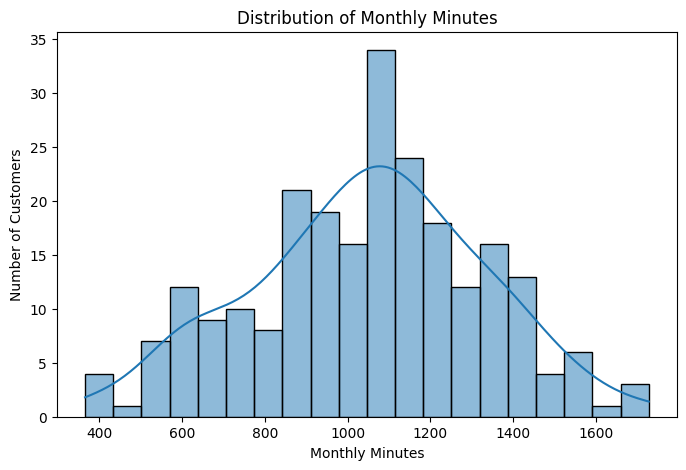

In [149]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='monthly_minutes',bins=20,kde=True)
plt.title('Distribution of Monthly Minutes')
plt.xlabel('Monthly Minutes')
plt.ylabel('Number of Customers')
plt.show()

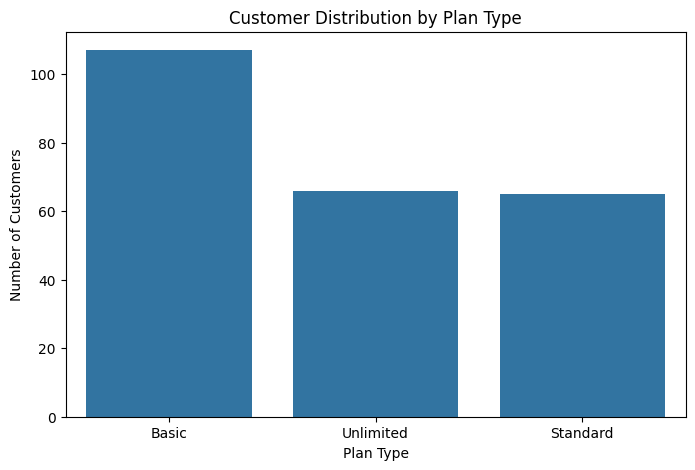

In [150]:
plt.figure(figsize=(8,5))

sns.countplot(data=df,x='plan_type',order=df['plan_type'].value_counts().index)

plt.title('Customer Distribution by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Number of Customers')

plt.show()

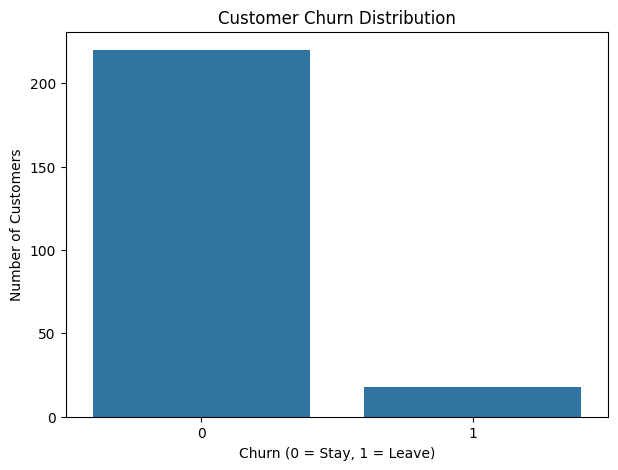

In [151]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='churn_next_month'
)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn (0 = Stay, 1 = Leave)')
plt.ylabel('Number of Customers')

plt.show()

##Bivariate analysis

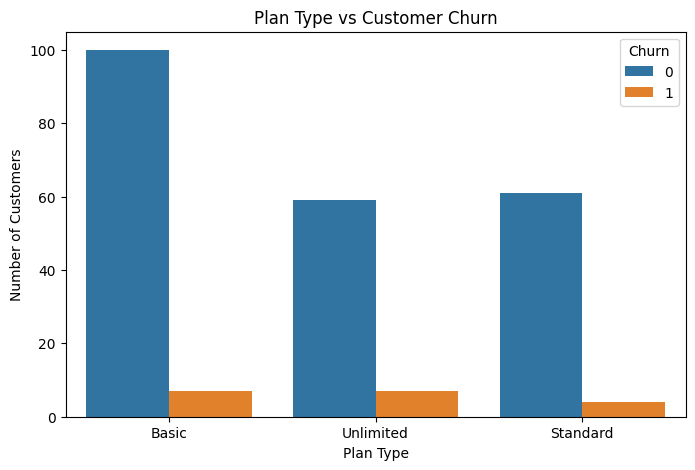

In [152]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='plan_type',
    hue='churn_next_month'
)

plt.title('Plan Type vs Customer Churn')
plt.xlabel('Plan Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

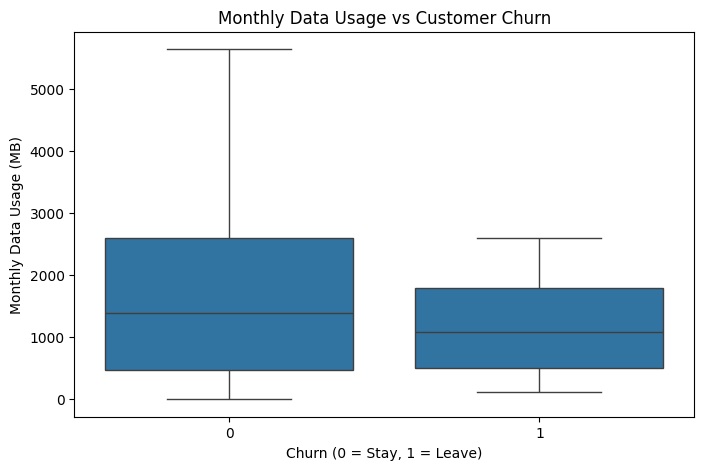

In [153]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='churn_next_month',
    y='monthly_data_mb'
)

plt.title('Monthly Data Usage vs Customer Churn')
plt.xlabel('Churn (0 = Stay, 1 = Leave)')
plt.ylabel('Monthly Data Usage (MB)')

plt.show()

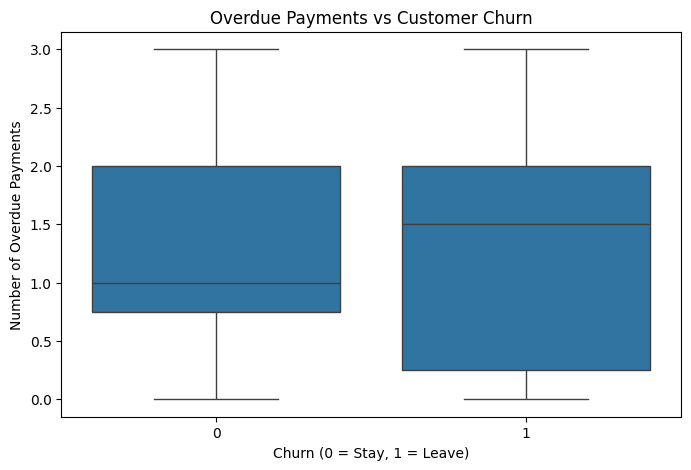

In [154]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='churn_next_month',
    y='overdue_payments'
)

plt.title('Overdue Payments vs Customer Churn')
plt.xlabel('Churn (0 = Stay, 1 = Leave)')
plt.ylabel('Number of Overdue Payments')

plt.show()

##Multivariate analysis

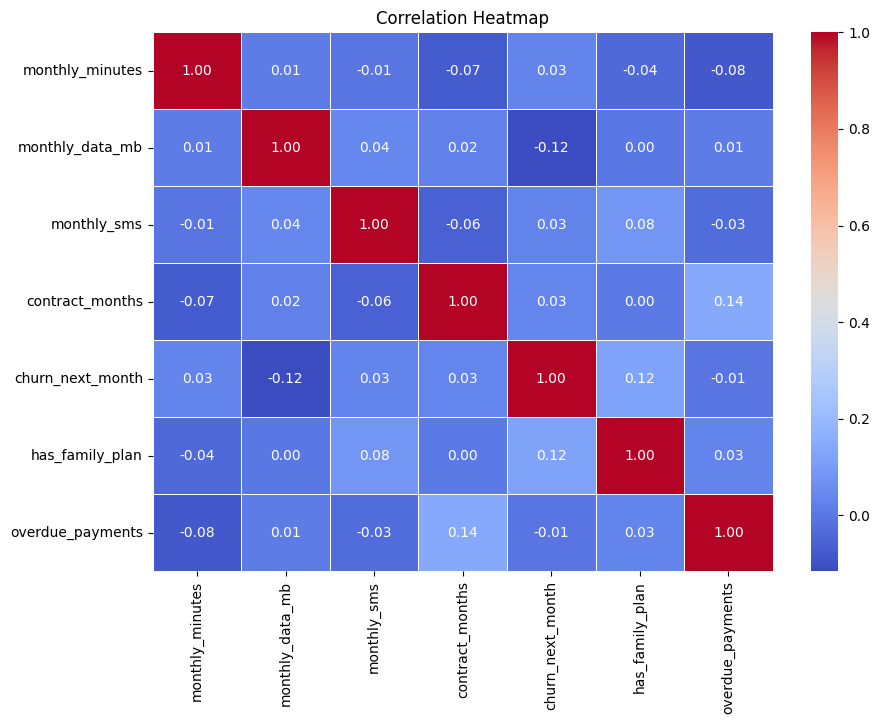

In [155]:
plt.figure(figsize=(10,7))

num_df = df.select_dtypes(include='number')

corr = num_df.corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.show()

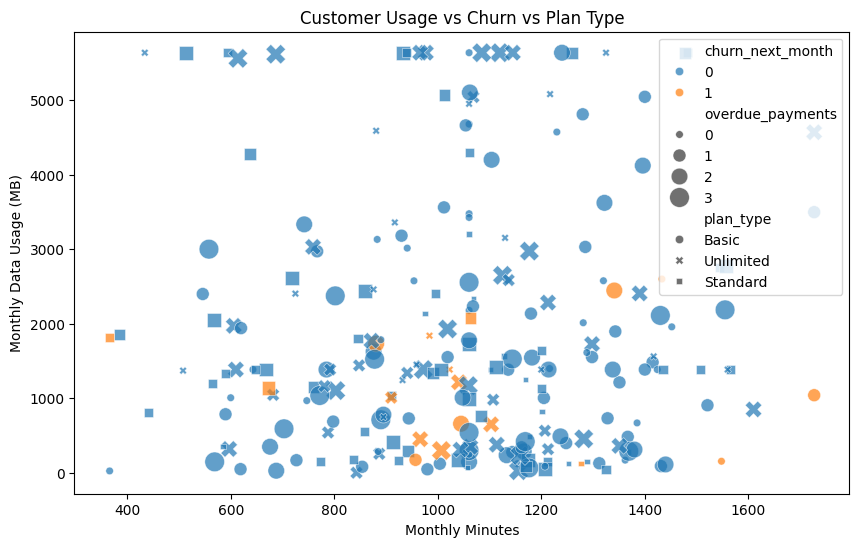

In [156]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='monthly_minutes',
    y='monthly_data_mb',
    hue='churn_next_month',
    style='plan_type',
    size='overdue_payments',
    sizes=(30,200),
    alpha=0.7
)

plt.title('Customer Usage vs Churn vs Plan Type')
plt.xlabel('Monthly Minutes')
plt.ylabel('Monthly Data Usage (MB)')

plt.show()